# 03_ EDA

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import pandas as pd
from src.config import PROCESSED_FILE
data=pd.read_csv(PROCESSED_FILE)

In [2]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'MonthlyCharges',
       'TotalCharges', 'Churn', 'InternetService_DSL',
       'InternetService_Fiber optic',
       'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='str')

En primer lugar, miraremos la distribución de abandono. Veremos si se trata de una clase desbalanceada y de esta forma podremos comparar con los distintos grupos. Intentaremos utilizar los mismos colores para Abandono/No Abandono.

In [3]:
# Colores fijos para todo el EDA: azul = se queda, naranja = churn
COLOR_NO = '#2a78d6'
COLOR_SI = '#eb6834'

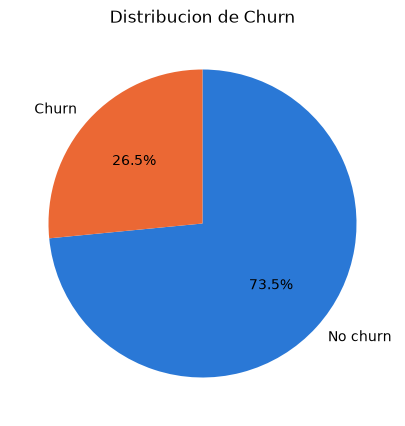

In [4]:
import matplotlib.pyplot as plt
conteo=data['Churn'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(5,5))
ax.pie(
    conteo,
    labels=['No churn','Churn'],
    colors=[COLOR_NO,COLOR_SI],
    autopct='%1.1f%%',
    startangle=90,
    counterclock=False
)
ax.set_title('Distribucion de Churn')
plt.show()

El abandono es una clase desbalanceada, corresponde con una cuarta parte de los usuarios aproximadamente. Veamos la distribución de abandono por Sexo y por Jubilado(Si/No)

In [5]:
distribucion_hombre=100*(data.gender.mean())
print(f"La distribución de hombres es del {distribucion_hombre}%")

print(f"La tasa de abandono por clase es:")
data.groupby('gender')['Churn'].mean()

La distribución de hombres es del 50.4756495811444%
La tasa de abandono por clase es:


gender
0    0.269209
1    0.261603
Name: Churn, dtype: float64

In [6]:
distribucion_senior=100*(data.SeniorCitizen.mean())
print(f"La distribución de jubilados es del {distribucion_senior}%")

print(f"La tasa de abandono por clase es:")
data.groupby('SeniorCitizen')['Churn'].mean()

La distribución de jubilados es del 16.21468124378816%
La tasa de abandono por clase es:


SeniorCitizen
0    0.236062
1    0.416813
Name: Churn, dtype: float64

En principio, el genero no parece significativo y se trata de unas variables que están bien distribuidas. Por otro lado, se evidencia una diferencia significativa en la tasa de abandono en personas jubiladas, que pasa de un 23,61% a un 41,68%.

## Boxplots para variables númericas

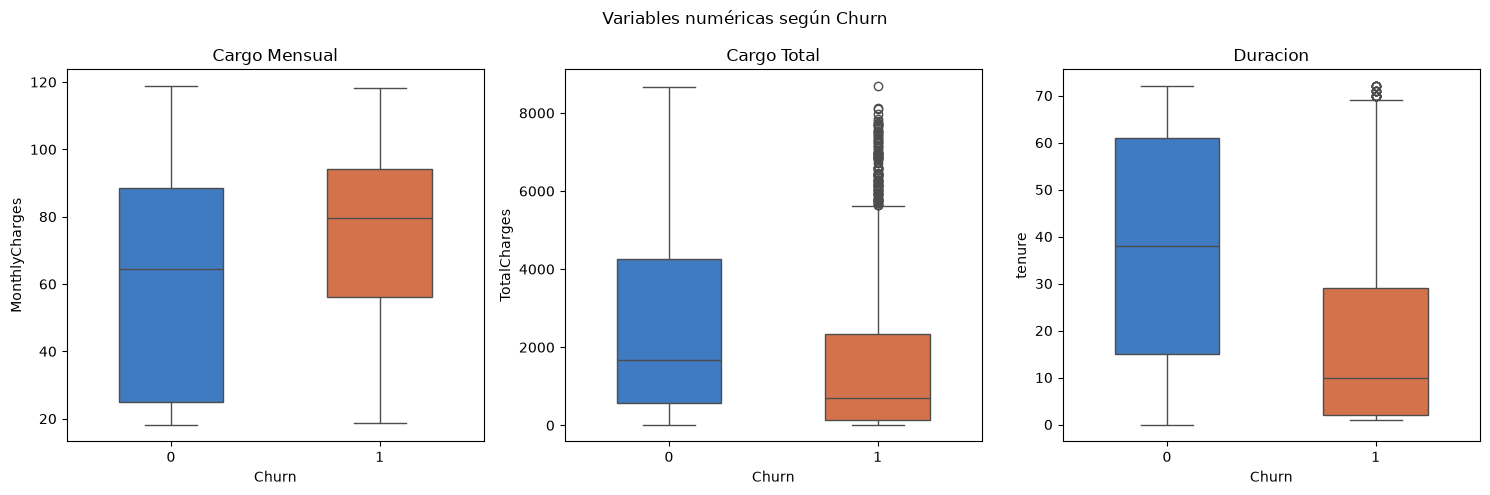

In [7]:
import seaborn as sns
variables_numericas=['MonthlyCharges','TotalCharges','tenure']
titulos= ['Cargo Mensual','Cargo Total','Duracion']
fig, axes= plt.subplots(1,3, figsize=(15,5))

for ax,col,titulo in zip (axes, variables_numericas,titulos):
    sns.boxplot(
        data=data,
        x='Churn',
        y=col,
        hue='Churn',
        palette=[COLOR_NO,COLOR_SI],
        legend=False,
        width=0.5,
        ax=ax
    )
    ax.set_title(titulo)

fig.suptitle('Variables numéricas según Churn')
plt.tight_layout()
plt.show()

**Conclusiones de los Boxplots**
1. Podemos observar que la distribución del cargo mensual es ligeramente mayor en aquellos que abandonan.

2. Las personas que llevan más tiempo pagando el servicio de forma general tienden a quedarse, no obstante, existen outliers en este campo.

3. La variable de cargo total tiene una mayor distribución también en aquellos que se mantienen, aunque esto seguramente se debe a que tienen también una mayor duración.

In [8]:
data.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'MonthlyCharges',
       'TotalCharges', 'Churn', 'InternetService_DSL',
       'InternetService_Fiber optic',
       'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check'],
      dtype='str')

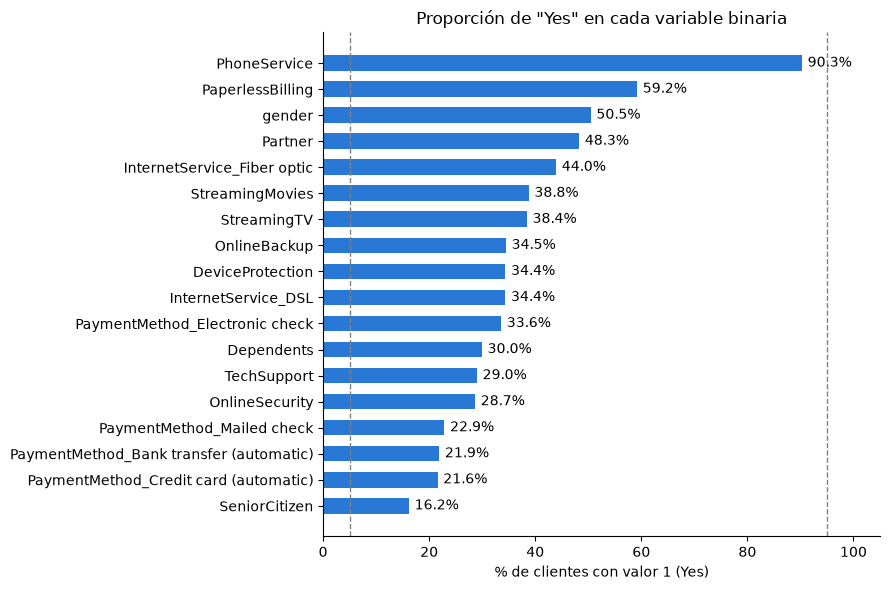

In [9]:
binarias = ['gender', 'SeniorCitizen', 'Partner', 'Dependents',
            'PhoneService', 'PaperlessBilling',
            'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
            'TechSupport', 'StreamingTV', 'StreamingMovies','InternetService_DSL',
       'InternetService_Fiber optic',
       'PaymentMethod_Bank transfer (automatic)',
       'PaymentMethod_Credit card (automatic)',
       'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']

# % de 1s en cada variable, ordenado de menor a mayor
pct_unos = (data[binarias].mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
barras = ax.barh(pct_unos.index, pct_unos.values, color=COLOR_NO, height=0.6)

# Etiqueta con el % al final de cada barra
ax.bar_label(barras, fmt='%.1f%%', padding=4, fontsize=10)

# Zona de "casi constante": por debajo del 5% o por encima del 95%
ax.axvline(5, color='grey', linestyle='--', linewidth=1)
ax.axvline(95, color='grey', linestyle='--', linewidth=1)

ax.set_xlim(0, 105)
ax.set_xlabel('% de clientes con valor 1 (Yes)')
ax.set_title('Proporción de "Yes" en cada variable binaria')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()


## DISTRIBUCIÓN DE VARIABLES BINARIAS POR ABANDONO O NO

                                         churn_si_0  churn_si_1  diferencia
variable                                                                   
OnlineSecurity                                 31.3        14.6       -16.7
TechSupport                                    31.2        15.2       -16.0
Dependents                                     31.3        15.5       -15.8
PaymentMethod_Credit card (automatic)          29.7        15.2       -14.4
Partner                                        33.0        19.7       -13.3
PaymentMethod_Bank transfer (automatic)        29.3        16.7       -12.6
InternetService_DSL                            30.5        19.0       -11.5
PaymentMethod_Mailed check                     28.7        19.1        -9.6
OnlineBackup                                   29.2        21.5        -7.6
DeviceProtection                               28.7        22.5        -6.1
gender                                         26.9        26.2        -0.8
PhoneService

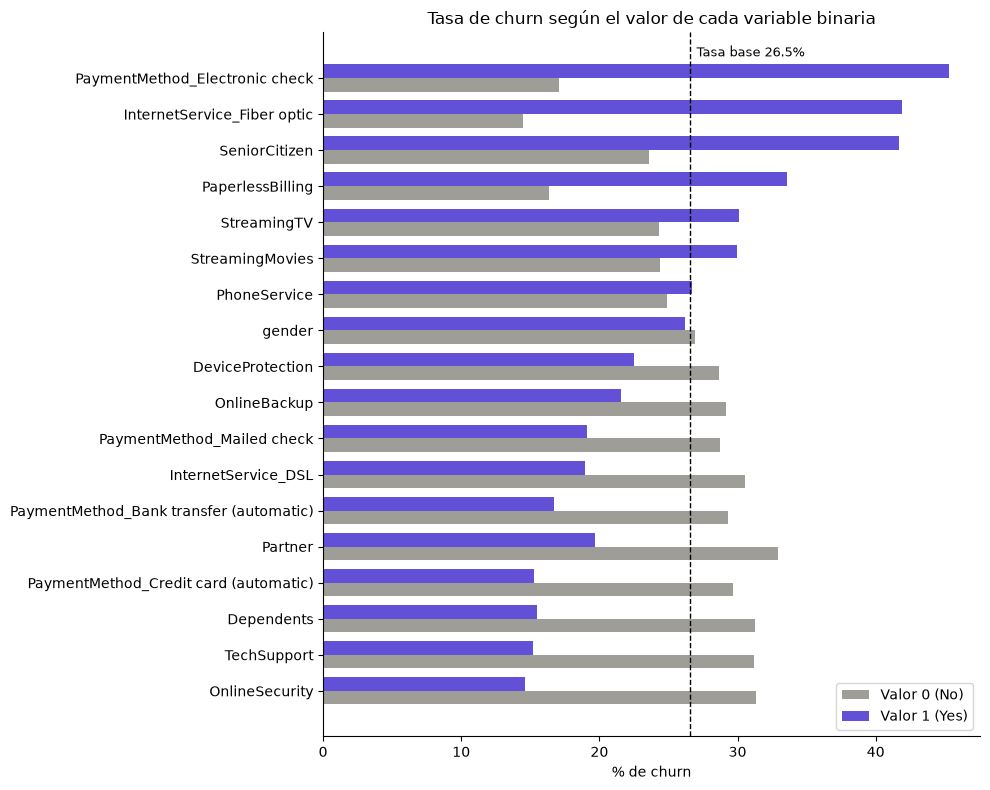

In [10]:
import numpy as np

# 1. Tabla con la tasa de churn cuando la variable vale 0 y cuando vale 1
filas = []
for col in binarias:
    filas.append({
        'variable': col,
        'churn_si_0': data.loc[data[col] == 0, 'Churn'].mean() * 100,
        'churn_si_1': data.loc[data[col] == 1, 'Churn'].mean() * 100,
    })

tabla = pd.DataFrame(filas).set_index('variable')
tabla['diferencia'] = tabla['churn_si_1'] - tabla['churn_si_0']
tabla = tabla.sort_values('diferencia')      # ordenadas por cuánto cambia el churn
print(tabla.round(1))

# 2. Gráfico de barras horizontales agrupadas
tasa_base = data['Churn'].mean() * 100
COLOR_0 = '#9e9d97'   # gris  = la variable vale 0 (No)
COLOR_1 = '#6250d6'   # violeta = la variable vale 1 (Yes)

y = np.arange(len(tabla))
alto = 0.38

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(y - alto/2, tabla['churn_si_0'], height=alto, color=COLOR_0, label='Valor 0 (No)')
ax.barh(y + alto/2, tabla['churn_si_1'], height=alto, color=COLOR_1, label='Valor 1 (Yes)')

ax.axvline(tasa_base, color='black', linestyle='--', linewidth=1)
ax.text(tasa_base + 0.5, len(tabla) - 0.4, f'Tasa base {tasa_base:.1f}%', fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(tabla.index)
ax.set_xlabel('% de churn')
ax.set_title('Tasa de churn según el valor de cada variable binaria')
ax.legend(loc='lower right')
ax.spines[['top', 'right']].set_visible(False)

plt.tight_layout()
plt.show()


Parece ser que clientes que utilizan un cheque electrónico o que tienen contratada fibra óptica tienden a abandonar más. 

Por otro lado, clientes con personas a su cargo, con seguridad online o con TechSupport tienden a quedarse más.

## HEATMAP

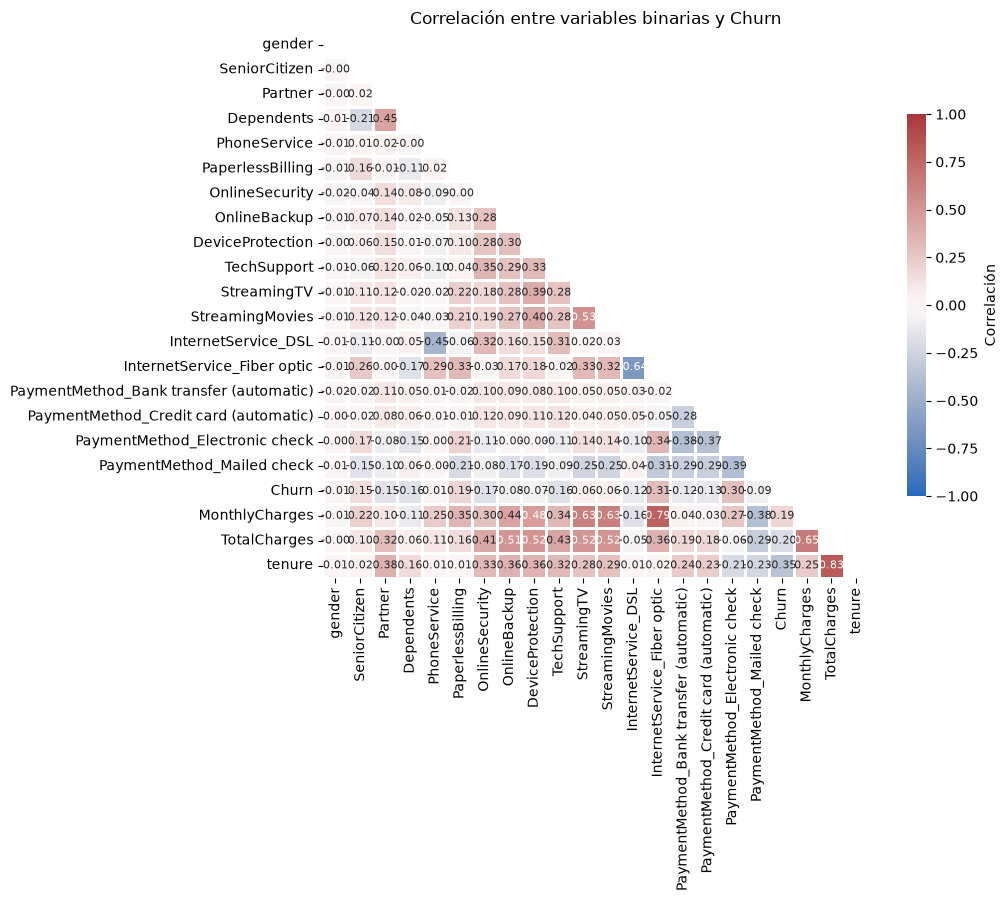

In [12]:
import numpy as np
import seaborn as sns

cols = binarias + ['Churn'] + variables_numericas          # añadimos Churn para ver también su relación con el objetivo
corr = data[cols].corr()

# Máscara para ocultar el triángulo superior (es un espejo del inferior)
mascara = np.triu(np.ones_like(corr, dtype=bool))

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    corr,
    mask=mascara,
    cmap='vlag',             # azul = negativa, rojo = positiva, gris claro = 0
    vmin=-1, vmax=1,         # escala fija de -1 a 1
    center=0,
    annot=True, fmt='.2f',   # escribe el valor en cada celda
    annot_kws={'size': 8},
    linewidths=1, linecolor='white',
    square=True,
    cbar_kws={'shrink': 0.7, 'label': 'Correlación'},
    ax=ax
)
ax.set_title('Correlación entre variables binarias y Churn')
plt.tight_layout()
plt.show()


No existen variables altamente correlacionadas entre sí. Esto es importante puesto que si tienen una corrleación muy elevada, posiblemente pueda eliminarse una de ellas.

Las variables que más correlación tienen entre ellas son la de cargo total junto con el tiempo que llevan con el servicio. Esto es lógico puesto que cuantos mas meses lleves contratando el servicio, más cantidad has pagado en total